# 01 — One-year NARX station-keeping results

**This notebook is the primary research result.** It replaces the obsolete two-controller and short-duration NARX analyses. Every time the notebook is fully executed, it generates or loads a **real 365-day** paired comparison and embeds the resulting figures in the notebook outputs so they appear directly on GitHub.

**Three observer-control alternatives:** uncontrolled, state-transition-matrix (STM) teacher-guided, and trained NARX-*inspired* learned guidance. Each receives the **same initial observer perturbation, initial EKF error, and epoch-indexed optical noise draws**. The LSOs provide real simulated angle observations for the EKF. Gateway follows the validated prescribed periodic 9:2 NRHO, with **zero Gateway maneuvers**.

**Interpretation:** Completing 365 days is not the same as maintaining the 100 km / 1 m/s observer departure corridor for every epoch. Gateway tracking is a separate estimation outcome. A single paired trajectory is a demonstration, not a reliable Monte Carlo success-rate estimate; increase `HALO_YEAR_ARCS` when appropriate.

## 1. Station-keeping and learning equations

The halo observer's *measured-state-based* navigation departure is

$$
\hat{\boldsymbol e}_{H,k} = \mathcal T(t_k)
\left(\hat{\boldsymbol x}_{H,k}-\boldsymbol x_H^*(t_k)\right).
$$

The three-component station-keeping impulse is either computed by STM nonlinear-validated guidance, $\Delta\boldsymbol v_{H,k}^{\mathrm{STM}}$, or estimated by a learned nonlinear autoregressive model with exogenous inputs:

$$
(\hat m_k,\widehat{\Delta\boldsymbol v}_{H,k},\hat\tau_k)
=F_\theta\left(\hat{\boldsymbol e}_{H,k:k-L+1},
\Delta\boldsymbol v_{H,k-1:k-L},\sin\phi_k,\cos\phi_k,
\mathrm{LSO\ visibility}_k,\mathrm{Gateway\ visibility}_k,P_{H,k}\right).
$$

The implementation currently uses gradient-boosted classification/regression with lagged features—a **NARX-inspired baseline rather than a recurrent neural NARX network**. Only the observer has a maneuver target. Gateway position and velocity tracking errors are computed from estimated minus prescribed-truth states, never as guidance targets.

In [1]:
import os
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from halo_tracking.study import load_config
from halo_tracking.closed_loop_narx import generate_closed_loop_dataset
from halo_tracking.two_stage_narx import evaluate_two_stage, fit_observer_policy
from halo_tracking.year_study import run_paired_study
from halo_tracking.gateway_reference_periodic import gateway_periodic_reference
from halo_tracking.orbit_reference import correct_halo_reference

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "configs/baseline.json").exists()), None)
if ROOT is None:
    raise RuntimeError("Open from a checkout of Halo_Orbit_Tracking")
cfg = load_config()
YEAR_DAYS = 365
YEAR_ARCS = int(os.environ.get("HALO_YEAR_ARCS", "1"))
YEAR_SEED = 24017
YEAR_CADENCE_S = float(os.environ.get("HALO_YEAR_CADENCE_S", "86400"))
YEAR_DECISIONS_PER_PERIOD = int(os.environ.get("HALO_YEAR_DECISIONS", "4"))
REUSE_YEAR_ARTIFACTS = os.environ.get("HALO_YEAR_REUSE", "0") == "1"
annual_dir = ROOT / "results/one_year"
training_dir = annual_dir / "teacher_training"
annual_dir.mkdir(parents=True, exist_ok=True)
gateway_at, gateway_metadata = gateway_periodic_reference(cfg)
observer_correction = correct_halo_reference(cfg)["orbit"]["correction"]
display(Markdown(
    f"**Validated CR3BP references:** observer closure {observer_correction['position_closure_km']:.3e} km; "
    f"Gateway closure {gateway_metadata['position_closure_km']:.3e} km / "
    f"{gateway_metadata['velocity_closure_m_s']:.3e} m/s. "
    f"Study: {YEAR_DAYS} days, {YEAR_ARCS} paired arc(s), "
    f"{YEAR_CADENCE_S/3600:.0f}-hour sampling."
))

**Validated CR3BP references:** observer closure 4.865e-08 km; Gateway closure 5.662e-06 km / 3.385e-08 m/s. Study: 365 days, 1 paired arc(s), 24-hour sampling.

## 2. Generate independent teacher-training data and fit observer NARX

Training uses complete short STM-controlled Monte Carlo trajectories (20/5/5 arcs by default) generated by the **LSO-driven EKF**. The learned model's classifier, three (Delta v) regressors, and burn-delay predictor are fitted **only on training trajectories**. Validation and test scores describe *offline imitation*; they are not closed-loop station-keeping results.

The held-out **one-year** rollouts below use separate random seeds and execute actual predictions without any STM fallback.

In [2]:
required = [training_dir / f"{split}.npz" for split in ("training", "validation", "test")]
if not (REUSE_YEAR_ARTIFACTS and all(p.exists() for p in required)):
    teacher_summary = generate_closed_loop_dataset(cfg, training_dir)
    print("Generated STM teacher training/validation/test arcs:", teacher_summary)
else:
    print("Reusing independent STM teacher data from the same annual experiment artifact.")
policy = fit_observer_policy(training_dir, cfg, annual_dir / "observer_narx.joblib")
offline = evaluate_two_stage(training_dir, annual_dir / "offline", cfg)
m = offline["observer"].get("test", {})
display(Markdown(
    "**Held-out short-arc observer model:** "
    f"maneuver F1 = {m.get('maneuver_f1', float('nan')):.3f}; "
    f"recall = {m.get('maneuver_recall', float('nan')):.3f}; "
    f"Δv RMSE = {m.get('delta_v_rmse_m_s', float('nan')):.3f} m/s. "
    "**These are label-imitation scores, not annual control performance.**"
))

Reusing independent STM teacher data from the same annual experiment artifact.


**Held-out short-arc observer model:** maneuver F1 = 0.533; recall = 0.444; Δv RMSE = 0.308 m/s. **These are label-imitation scores, not annual control performance.**

## 3. Run the matched 365-day closed-loop experiment

The three cases are fully propagated with the same source noise and initial conditions. A trajectory can terminate early after an excessive departure or numerical failure; remaining days are **not simulated** and are counted as unsuccessful, rather than presented as zero tracking error.

For reproducibility, the notebook runs one paired full-year pilot by default. For a stronger ensemble, set environment variable `HALO_YEAR_ARCS=5` (or higher) and rerun; results from one arc must never be described as statistical reliability.

In [3]:
summary_path = annual_dir / "summary.json"
reuse_ok = False
if REUSE_YEAR_ARTIFACTS and summary_path.exists():
    candidate = json.loads(summary_path.read_text())
    reuse_ok = (candidate.get("days") == YEAR_DAYS
                and candidate.get("arcs") == YEAR_ARCS
                and candidate.get("seed") == YEAR_SEED
                and candidate.get("measurement_cadence_s") == YEAR_CADENCE_S
                and candidate.get("decisions_per_period") == YEAR_DECISIONS_PER_PERIOD
                and all((annual_dir / f"{name}_arc_{i:03d}.npz").exists()
                        for name in ("uncontrolled", "stm", "narx") for i in range(YEAR_ARCS)))
if reuse_ok:
    annual = candidate
    print("Loaded verified 365-day paired trajectories from workflow artifacts.")
else:
    annual = run_paired_study(
        cfg, annual_dir, policy, days=YEAR_DAYS, arcs=YEAR_ARCS,
        seed=YEAR_SEED, measurement_cadence_s=YEAR_CADENCE_S,
        decisions_per_period=YEAR_DECISIONS_PER_PERIOD)
    print("Completed new matched 365-day simulation.")
assert annual["days"] == 365
display(Markdown(
    f"**Actual simulation:** {annual['arcs']} paired 365-day arc(s). "
    "Plots and tables below use saved trajectory arrays, not illustrative values."
))

Loaded verified 365-day paired trajectories from workflow artifacts.


**Actual simulation:** 1 paired 365-day arc(s). Plots and tables below use saved trajectory arrays, not illustrative values.

## 4. One-year results and failure accounting

The full-year completion rate means the numerical trajectory reached day 365. The **corridor-success** rate is stricter: both observer position and velocity departure must remain within their tolerances at **all** decision epochs, with no early termination. Gateway tracking RMSE after early termination covers only the observed interval and is not directly comparable to a full-year RMSE.

Each entry below refers to actual executed controls; an early cutoff is shown explicitly.

In [4]:
table = [
    "| Controller | Reached day 365 | Corridor success | First corridor exit (day) | Last simulated day | Executed Δv (m/s) | Gateway position RMSE* (m) |",
    "|---|---|---|---:|---:|---:|---:|"
]
for x in annual["arc_metrics"]:
    if x["arc"] != 0:
        continue
    path = annual_dir / f"{x['controller']}_arc_000.npz"
    with np.load(path) as d:
        good = np.isfinite(d["observer_truth_position_departure_km"])
        last_day = float(d["day"][np.flatnonzero(good)[-1]]) if good.any() else float("nan")
    exit_day = "none" if x["first_corridor_exit_day"] is None else f"{x['first_corridor_exit_day']:.1f}"
    rmse = "N/A" if x["gateway_position_rmse_km"] is None else f"{1000*x['gateway_position_rmse_km']:.1f}"
    table.append(
        f"| {x['controller']} | {x['completed_full_span']} | "
        f"{x['maintained_corridor_full_year']} | {exit_day} | {last_day:.1f} | "
        f"{x['delta_v_total_m_s']:.2f} | {rmse} |"
    )
display(Markdown("\n".join(table)))
display(Markdown(
    "*The Gateway RMSE reported for trajectories that terminated early is "
    "calculated only over their available simulated epochs. The ensemble summary "
    "is stored in `results/one_year/summary.json` and "
    "`results/one_year/arc_metrics.csv`."
))
summary_rows = ["| Controller | Paired arcs | Full-span completion rate | Entire-year corridor success rate | Median total Δv (m/s) |",
                "|---|---:|---:|---:|---:|"]
for name, data in annual["aggregate"].items():
    summary_rows.append(f"| {name} | {data['arcs']} | "
                        f"{data['full_span_completion_rate']:.1%} | "
                        f"{data['full_year_corridor_success_rate']:.1%} | "
                        f"{data['median_total_delta_v_m_s']:.2f} |")
display(Markdown("**Paired Monte Carlo summary** (limited by ensemble size):\n\n" +
                 "\n".join(summary_rows)))

| Controller | Reached day 365 | Corridor success | First corridor exit (day) | Last simulated day | Executed Δv (m/s) | Gateway position RMSE* (m) |
|---|---|---|---:|---:|---:|---:|
| uncontrolled | False | False | 6.0 | 44.1 | 0.00 | 559.8 |
| stm | True | False | 24.1 | 365.0 | 68.74 | 213.7 |
| narx | False | False | 6.0 | 38.1 | 5.76 | 594.3 |

*The Gateway RMSE reported for trajectories that terminated early is calculated only over their available simulated epochs. The ensemble summary is stored in `results/one_year/summary.json` and `results/one_year/arc_metrics.csv`.

**Paired Monte Carlo summary** (limited by ensemble size):

| Controller | Paired arcs | Full-span completion rate | Entire-year corridor success rate | Median total Δv (m/s) |
|---|---:|---:|---:|---:|
| uncontrolled | 1 | 0.0% | 0.0% | 0.00 |
| stm | 1 | 100.0% | 0.0% | 68.74 |
| narx | 1 | 0.0% | 0.0% | 5.76 |

## 5. One-year observer departure and executed station-keeping Δv

The horizontal lines are the 100 km and 1 m/s **observer departure** limits. Curves that terminate before 365 days represent a failure/cutoff, **not** a zero-valued trajectory afterward. The accumulated Δv curve stops when simulation stops; a smaller value from a failed controller is not evidence of better station-keeping.

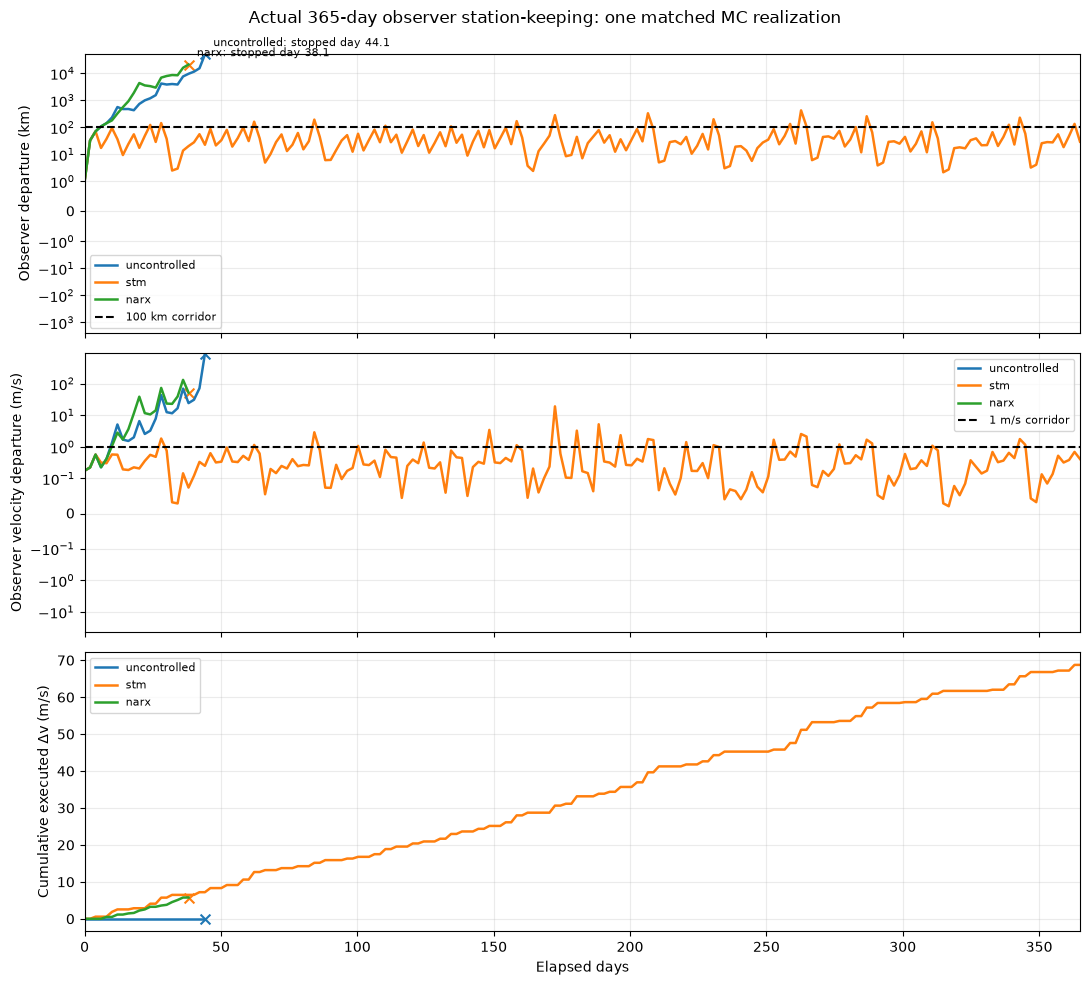

In [5]:
policies = ("uncontrolled", "stm", "narx")
hist = {}
for name in policies:
    with np.load(annual_dir / f"{name}_arc_000.npz") as d:
        hist[name] = {key: np.asarray(d[key]) for key in d.files}
fig, axs = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
for name in policies:
    d = hist[name]
    t = d["day"]
    p = d["observer_truth_position_departure_km"]
    v = d["observer_truth_velocity_departure_m_s"]
    delta_v = np.cumsum(np.linalg.norm(d["applied_delta_v_rotating_m_s"], axis=-1))
    good = np.isfinite(p)
    for axis, y in zip(axs, (p, v, delta_v)):
        axis.plot(t[good], y[good], linewidth=1.8, label=name)
        if not good.all() and good.any():
            last = np.flatnonzero(good)[-1]
            axis.scatter([t[last]], [y[last]], marker="x", s=50)
    if not good.all() and good.any():
        last = np.flatnonzero(good)[-1]
        axs[0].annotate(f"{name}: stopped day {t[last]:.1f}",
                        xy=(t[last], p[last]), xytext=(6, 6),
                        textcoords="offset points", fontsize=8)
axs[0].axhline(100., color="black", ls="--", label="100 km corridor")
axs[1].axhline(1., color="black", ls="--", label="1 m/s corridor")
for axis, label in zip(axs, (
        "Observer departure (km)",
        "Observer velocity departure (m/s)",
        "Cumulative executed Δv (m/s)")):
    axis.set_ylabel(label)
    axis.grid(alpha=.25)
    axis.legend(fontsize=8)
axs[0].set_yscale("symlog", linthresh=1)
axs[1].set_yscale("symlog", linthresh=.1)
axs[-1].set_xlabel("Elapsed days")
axs[-1].set_xlim(0., 365.)
fig.suptitle("Actual 365-day observer station-keeping: one matched MC realization")
plt.tight_layout()
fig.savefig(annual_dir / "observer_departure_and_delta_v.png", dpi=140)
plt.show()

## 6. Gateway tracking during the same one-year trajectories

Gateway receives **no station-keeping commands**. The optical EKF uses LSO-informed observer navigation and accepted camera observations to estimate Gateway. The plots show position and velocity estimation error *only at epochs that were actually simulated*. The 100 m and 0.01 m/s lines are simultaneous tracking goals, not guaranteed accuracy.

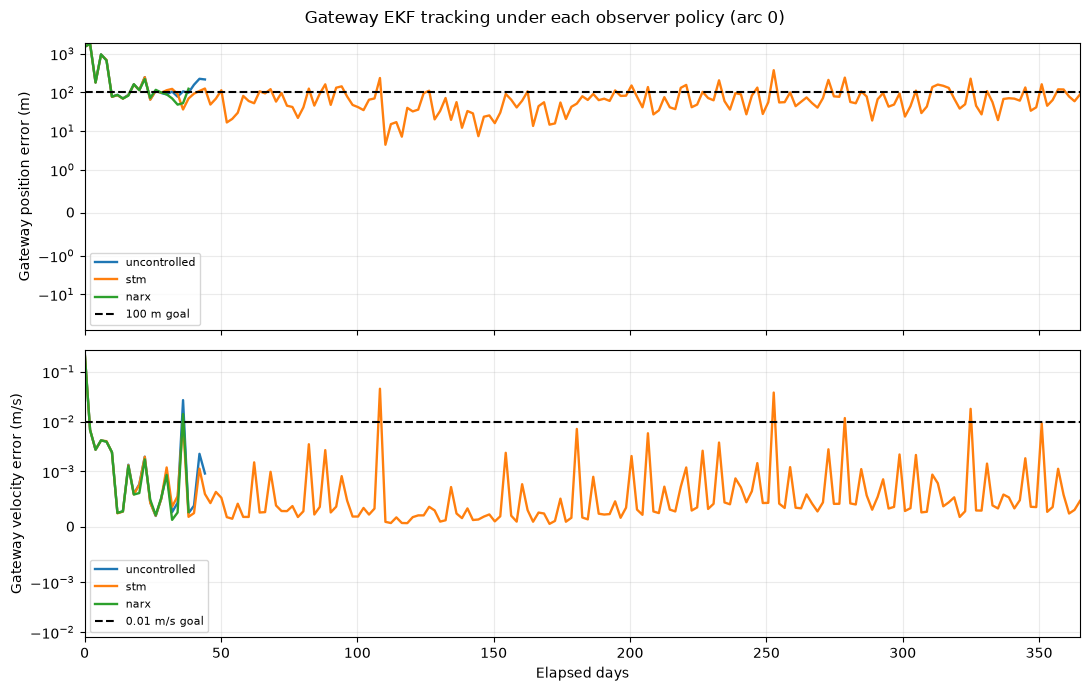

In [6]:
fig, axs = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for name in policies:
    d = hist[name]
    t = d["day"]
    ep = d["gateway_tracking_position_error_km"] * 1000
    ev = d["gateway_tracking_velocity_error_m_s"]
    valid = np.isfinite(ep) & np.isfinite(ev)
    axs[0].plot(t[valid], ep[valid], label=name, linewidth=1.7)
    axs[1].plot(t[valid], ev[valid], label=name, linewidth=1.7)
axs[0].axhline(100., color="black", ls="--", label="100 m goal")
axs[1].axhline(.01, color="black", ls="--", label="0.01 m/s goal")
axs[0].set_ylabel("Gateway position error (m)")
axs[1].set_ylabel("Gateway velocity error (m/s)")
axs[1].set_xlabel("Elapsed days")
axs[1].set_xlim(0., 365.)
for ax in axs:
    ax.set_yscale("symlog", linthresh=1 if ax is axs[0] else .001)
    ax.grid(alpha=.25)
    ax.legend(fontsize=8)
fig.suptitle("Gateway EKF tracking under each observer policy (arc 0)")
plt.tight_layout()
fig.savefig(annual_dir / "gateway_tracking_errors.png", dpi=140)
plt.show()

## Interpretation and next experiment

This is a **full-year executed-control pilot**, not a claim of reliable NARX station-keeping. Report the STM and learned-controller outcomes separately and count any early termination as failure. Increase the **independent one-year** paired test arcs before estimating success probabilities or annual Δv distributions.

From the repository root, the full five-pair experiment is:

```bash
python scripts/run_one_year_study.py --days 365 --arcs 5
```

Then set `HALO_YEAR_ARCS=5` and `HALO_YEAR_REUSE=1` when executing this notebook to display the full-ensemble summary. Use the script's archived NPZ and JSON outputs as the authoritative numerical data. This is an idealized CR3BP/synthetic-optics study; the stated 9:2 Gateway reference is validated for periodic CR3BP closure, **not** independent orbit-family provenance or operational ephemeris fidelity.